In [2]:
# SPDX-FileCopyrightText: Copyright (c) 2025 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
# SPDX-License-Identifier: CC-BY-NC-SA-4.0
#
# This work is licensed under a Creative Commons Attribution-NonCommercial-ShareAlike
# 4.0 International License. https://creativecommons.org/licenses/by-nc-sa/4.0/


import argparse
import os
import yaml
import importlib
from pathlib import Path
from PIL import Image
from typing import Any, Dict

import numpy as np
import torch

import matplotlib.pyplot as plt
import cv2

from utils import flow_viz
from utils import flow_utils

In [25]:
data_root = "/network-volume/nhphuc/dataset"
image1_path = f"{data_root}/endonerf/pulling_soft_tissues/images/frame-000046.color.png"
image2_path = f"{data_root}/endonerf/pulling_soft_tissues/images/frame-000047.color.png"
depth1_path = f"{data_root}/endonerf/pulling_soft_tissues/fs_depth/frame-000046.color.npy"
depth2_path = f"{data_root}/endonerf/pulling_soft_tissues/fs_depth/frame-000047.color.npy"
# depth1_path = f"{data_root}/endonerf/pulling_soft_tissues/depth/frame-000046.depth.png"
# depth2_path = f"{data_root}/endonerf/pulling_soft_tissues/depth/frame-000047.depth.png"
mask1_path = f"{data_root}/endonerf/pulling_soft_tissues/masks/frame-000046.mask.png"
mask2_path = f"{data_root}/endonerf/pulling_soft_tissues/masks/frame-000047.mask.png"
intrinsics_path = f"{data_root}/endonerf/pulling_soft_tissues/K.npy"

def load_mask(mask_path):
    mask = Image.open(mask_path).convert("L")
    mask = np.array(mask).astype(np.float32) / 255.0
    if "stereomis" not in mask_path:
        mask = 1.0 - mask
    mask = mask > 0
    return torch.from_numpy(mask).cuda().bool()

def load_depth(depth_path):
    if depth_path.endswith(".npy"):
        depth = np.load(depth_path)
    elif depth_path.endswith(".png"):
        depth = np.array(Image.open(depth_path)).astype(np.float32)

    close_depth = np.percentile(depth[depth!=0], 3.0)
    inf_depth = np.percentile(depth[depth!=0], 99.8)
    depth = np.clip(depth, close_depth, inf_depth) 

    return torch.from_numpy(depth).float()

image1 = (torch.from_numpy(np.array(Image.open(image1_path).convert('RGB'))) / 255.0).permute(2, 0, 1)  # Convert to CxHxW
image2 = (torch.from_numpy(np.array(Image.open(image2_path).convert('RGB'))) / 255.0).permute(2, 0, 1)  # Convert to CxHxW
depth1 = load_depth(depth1_path)
depth2 = load_depth(depth2_path)
mask1 = load_mask(mask1_path)
mask2 = load_mask(mask2_path)
K = torch.from_numpy(np.load(intrinsics_path))
P = torch.eye(4)  # Assuming identity for simplicity; replace with actual pose if available

In [52]:
from flow_models import get_scene_flow_model
sfmodel = get_scene_flow_model("zmsf")
# sfmodel = get_scene_flow_model("expansion", model_path="weights/expansion/exp-kitti-trainval/exp-kitti-trainval.pth")
# sfmodel = get_scene_flow_model("expansion")

Loading model from config: thirdparty/zmsf/zmsf/configs/zmsf_shift+dynamicreplica+vkitti+kubric+pointodyssey+spring_adap_241106.yaml
Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


/network-volume/nhphuc/EndoFlow/thirdparty/zmsf/zmsf/eval_models/st3r.py:60: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(weight_path)["state_dict"]

In [53]:
with torch.no_grad():
    scene_flow = sfmodel.forward(
        image1[None].cuda(),
        image2[None].cuda(),
        depth1[None].cuda(),
        depth2[None].cuda(),
        K[None].cuda(),
        K[None].cuda(),
        P[None].cuda(),
        P[None].cuda(),
    )

projected_optical_flow, _ = flow_utils.scene_flow_to_optical_flow(
    scene_flow.permute(2, 0, 1)[None],  # (1, 3, H, W)
    depth1[None, None].cuda(), 
    K[None].cuda(), 
    K[None].cuda(), 
    P[None].cuda(),
    P[None].cuda(),
    visible=None,
    remove_occ=False
)

/network-volume/nhphuc/EndoFlow/thirdparty/zmsf/zmsf/model.py:133: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


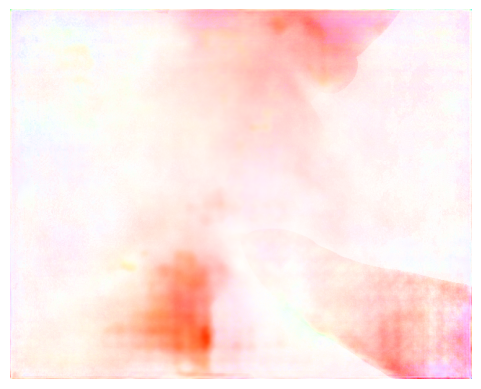

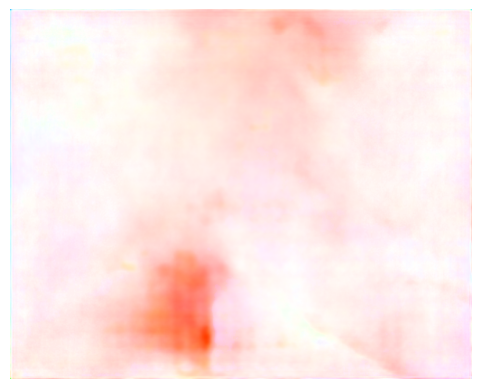

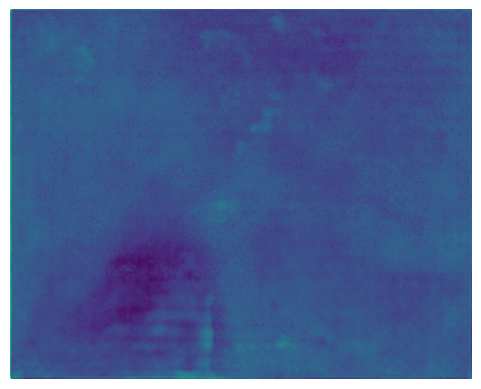

In [54]:
from utils import flow_viz
importlib.reload(flow_viz)

projected_optical_flow_image = flow_viz.optical_flow_to_image(
    projected_optical_flow[0].permute(1, 2, 0).cpu().numpy(),
    percentile=100
)
xy_flow_image, z_flow_image = flow_viz.scene_flow_to_image(
    scene_flow.cpu().numpy(),
    percentile=100
)

plt.imshow(projected_optical_flow_image)
plt.axis('off')
plt.show()

plt.imshow(xy_flow_image)
plt.axis('off')
plt.show()

plt.imshow(z_flow_image)
plt.axis('off')
plt.show()

In [8]:
from flow_models import OpticalFlowModel
ofnet = OpticalFlowModel("flowseek_m", "tar-c-t")

2026-08-24 17:05:33.125 | INFO     | ptlflow:restore_model:283 - Restored model state from checkpoint: tar-c-t


In [9]:
with torch.no_grad():
    forward_optical_flow = ofnet.forward(image1.cuda(), image2.cuda())
    backward_optical_flow = ofnet.forward(image2.cuda(), image1.cuda())

In [28]:
importlib.reload(flow_utils)

scene_flow, valid_mask = flow_utils.compute_scene_flow_world(
    depth1[None, None].cuda(), # (1, 1, H, W)
    depth2[None, None].cuda(), # (1, 1, H, W)
    forward_optical_flow.permute(2, 0, 1)[None], # (1, 2, H, W)
    backward_optical_flow.permute(2, 0, 1)[None],  # (1, 2, H, W)
    mask1[None, None].cuda(), # (1, 1, H, W)
    mask2[None, None].cuda(), # (1, 1, H, W)
    K[None].cuda(), 
    K[None].cuda(),
    P[None].cuda(),
    P[None].cuda(),
    remove_occ=False,
    reject_motion_outliers=True,
)

projected_optical_flow, _ = flow_utils.scene_flow_to_optical_flow(
    scene_flow, 
    depth1[None, None].cuda(), 
    K[None].cuda(), 
    K[None].cuda(), 
    P[None].cuda(),
    P[None].cuda(),
    valid_mask,
    remove_occ=False
)

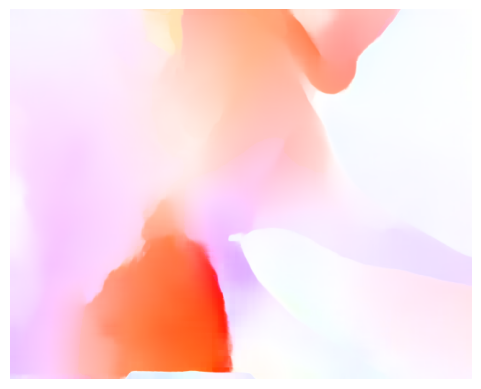

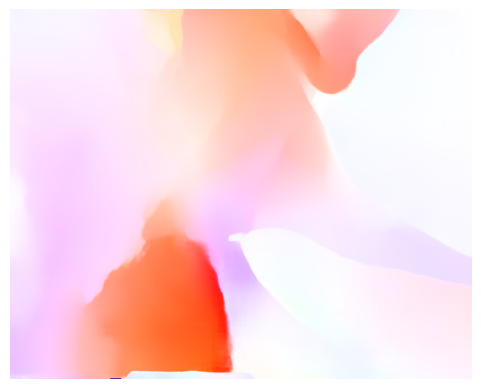

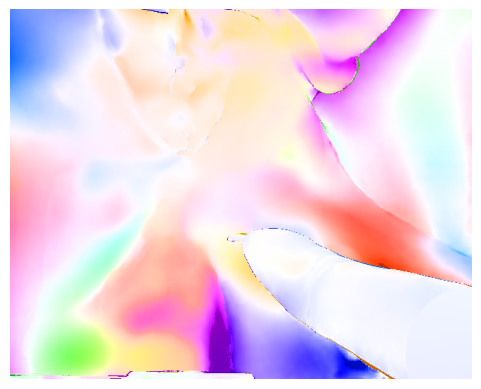

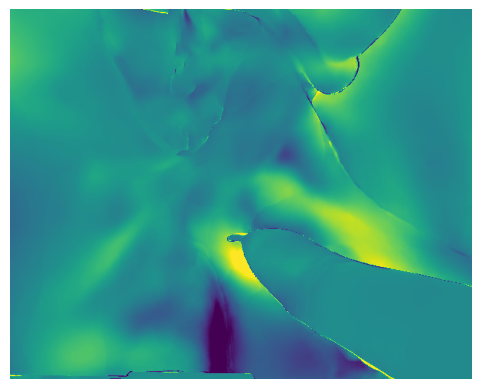

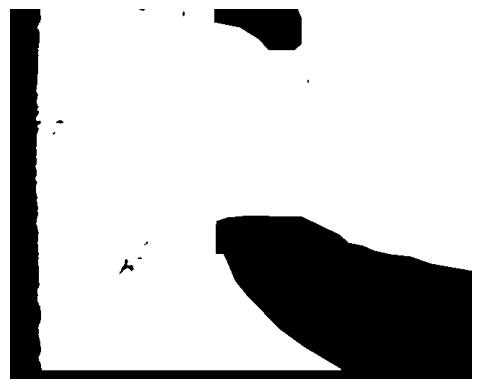

In [43]:
from utils import flow_viz
importlib.reload(flow_viz)

optical_flow_image = flow_viz.optical_flow_to_image(forward_optical_flow.cpu().numpy(), percentile=100)
projected_optical_flow_image = flow_viz.optical_flow_to_image(projected_optical_flow[0].permute(1, 2, 0).cpu().numpy(), percentile=99.995)

xy_flow_image, z_flow_image = flow_viz.scene_flow_to_image(scene_flow[0].permute(1, 2, 0).cpu().numpy(), percentile=99)

plt.imshow(optical_flow_image)
plt.axis('off')
plt.show()

plt.imshow(projected_optical_flow_image)
plt.axis('off')
plt.show()

plt.imshow(xy_flow_image)
plt.axis('off')
plt.show()

plt.imshow(z_flow_image)
plt.axis('off')
plt.show()

plt.imshow(mask1.cpu().numpy(), cmap='gray')
plt.axis('off')
plt.show()

In [10]:
# scene_flow.quantile(0.995)
scene_flow.max()

tensor(62.5705, device='cuda:0')